# 백오프 큐 동시성

**이 노트북에서 할 일**

1. 늘 429를 보내는 연습용 서버를 띄우고, 모델 객체를 한 번 부를 때 서버에 가는 요청 수를 셉니다.
2. 다시 보내기를 두 곳에 겹친 코드(Before)와 한 곳에만 둔 코드(After)의 요청 수를 견줍니다.
3. 문의 다섯을 한꺼번에 보낼 때, 값 `max_concurrency` 하나만 바꿔 한꺼번에 처리되는 수를 봅니다.

**준비물** — 이 노트북은 OpenAI 서비스에 요청을 보내지 않고, API 키도 읽지 않습니다.
모델 객체는 가짜 키로 만들고, 요청은 이 컴퓨터 안의 연습용 서버로만 보냅니다.
연습용 서버는 실습 폴더 `notebooks/`의 파일 `always_429_server.py`입니다.
이 서버는 어떤 요청에도 상태 코드 429만 보내고, 모델의 답은 보내지 않습니다.
제공자의 요청 제한을 흉내 낸 서버라, 이 절의 429는 제공자가 보낸 것이 아닙니다.

노트북이 이 서버를 자식 프로세스로 띄우고, 마지막 셀에서 끕니다.
서비스에 보내는 요청이 없어 요금은 들지 않습니다.
다시 보내기 전에 기다리는 셀이 있어, 몇 셀은 곧바로 끝나지 않습니다.
걸린 시간은 재지 않았고, 이 노트북은 파일을 쓰지 않습니다.
실습 폴더의 도구 파일 `cost_tools.py`에서 함수 하나를 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
셋은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
나머지 둘은 openai 3.13.0과 httpx 0.28.1입니다.
다섯 모두 실습 폴더 잠금과 같은 버전입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2절의 연습용 서버와 3절의 요청 수를 함께 봅니다.
4절 Before와 5절 After, 6절 값 바꿔 보기는 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch34-cost-rate-limits`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

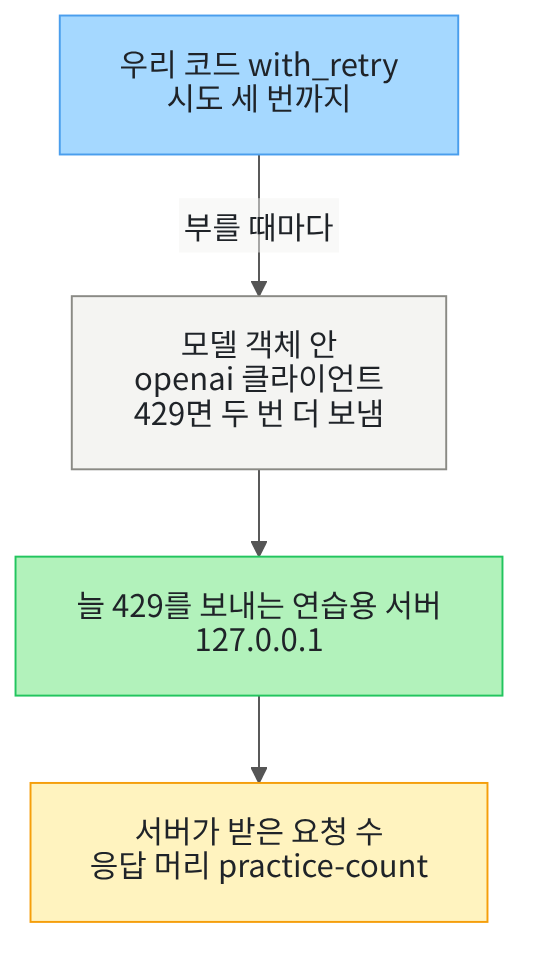

위에서 아래로 읽습니다.
파란 상자는 우리가 붙이는 다시 보내기 규칙이고, 회색 상자는 라이브러리 안에서 다시 보내는 곳입니다.
초록 상자는 이 절이 띄우는 연습용 서버이고, 노란 상자는 서버가 알려 준 수를 노트북이 출력한 값입니다.
두 곳이 한 줄로 이어져 있어, 위 상자가 한 번 부를 때마다 아래 상자가 요청을 여러 번 보낼 수 있습니다.

## 1. 준비

제목의 백오프는 다시 보내기 전에 기다리는 시간을 두 배씩 늘리는 방법입니다.
큐는 차례를 기다리는 대기열이고, 동시성은 한꺼번에 보내는 요청의 수입니다.
이 절은 세 말을 제목에만 두고, 본문에서는 풀어 쓴 말을 씁니다.

요청 제한(rate limit)은 제공자가 정한 분당 요청 수와 토큰 수의 상한입니다.
Ch 6 05절에서 배운 말이고, 상한을 넘은 요청은 상태 코드 429를 받습니다.
요청이 실패했을 때 같은 요청을 다시 보내는 일은 다시 보내기(재시도)라고 부릅니다.
Ch 6 05절의 「다시 시도」와 같은 뜻입니다.

첫 셀은 패키지 다섯을 설치하고 설치된 버전을 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "openai==3.13.0" "httpx==0.28.1"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("httpx:", version("httpx"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.13.0
httpx: 0.28.1


**결과 읽기** — 출력 줄 `openai: 3.13.0`과 `httpx: 0.28.1`이 보입니다.
패키지 openai는 LangChain 모델 객체가 요청을 보낼 때 쓰는 OpenAI 클라이언트입니다.
패키지 httpx는 Ch 28 03절에서 쓴 HTTP 요청 도구로, 연습용 서버에 센 수를 물을 때 씁니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
Ch 28 03절에서 배운 함수 `wait_for_port`는 도구 파일 `cost_tools.py`에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os·subprocess·sys는 Python에 들어 있는 모듈입니다)
import os
import subprocess
import sys
import httpx
from langchain.chat_models import init_chat_model
from langchain_core.exceptions import ModelRateLimitError
from langchain_core.runnables import RunnableLambda
# Ch 28 03절에서 배운 함수는 도구 파일에서 가져옵니다
from cost_tools import wait_for_port

print("가져온 모듈:", "os, subprocess, sys, httpx")
print("도구 파일에서 가져온 함수:", wait_for_port.__name__)

가져온 모듈: os, subprocess, sys, httpx
도구 파일에서 가져온 함수: wait_for_port


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: wait_for_port`가 보입니다.
이 함수는 Ch 28 03절 셀의 함수를 주석과 본문 글자 그대로 옮긴 것으로, 이 절에서 도구 파일에 더했습니다.
이름 `ModelRateLimitError`는 LangChain이 요청 제한 오류에 붙인 공통 이름입니다.
Ch 6 05절의 `ModelTimeoutError`와 같은 곳에 있습니다.

앞에서 배운 함수는 `cost_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

이 절은 모델 서비스에 요청을 보내지 않아, 키를 읽는 셀을 두지 않았습니다.

## 2. 늘 429를 보내는 연습용 서버

실제 요청 제한은 조직과 프로젝트마다 정해지고, 교재 실습의 요청 몇 번으로는 닿지 않습니다.
그래서 이 절은 연습용 서버를 이 컴퓨터 안에 띄웁니다.
연습용 서버는 어떤 요청이 와도 상태 코드 429만 보내는 작은 서버입니다.
소방 훈련의 연습용 경보처럼, 진짜 불은 없어도 대응은 실제로 해 봅니다.
Ch 16 05절의 실패 흉내처럼 제공자의 요청 제한을 흉내 내고, 모델의 답은 보내지 않습니다.

서버는 받은 요청 가운데 모델에 보내는 요청만 셉니다.
센 수는 응답 머리 `practice-count`에 적어 보냅니다.
머리는 HTTP 응답에서 본문 앞에 붙는 이름과 값 줄입니다.
주소 끝이 `/reset`인 요청을 받으면, 서버는 센 수를 0으로 맞춥니다.

다음 셀은 실습 폴더의 위치를 찾습니다.
연습용 서버 파일이 실습 폴더 `notebooks/`에 있기 때문입니다.

In [3]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch34-cost-rate-limits"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/notebooks/always_429_server.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
첫 후보 `..`는 `notebooks/` 폴더에서 열었을 때 맞는 자리입니다.
둘째 `.`는 실습 폴더 맨 위, 셋째는 프로젝트 맨 위에서 열었을 때 맞습니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.

다음 셀은 서버를 띄울 포트와 주소, 명령을 정합니다.
포트는 한 컴퓨터 안에서 프로그램마다 나눠 쓰는 번호입니다.
띄우기 전에 Ch 28 03절처럼, 그 포트에서 이미 듣는 프로그램이 있는지 봅니다.
함수 `wait_for_port`는 정한 초 동안 포트에 연결해 보고, 열려 있으면 `True`를 내놓습니다.

In [4]:
# 서버 파일 위치·포트·주소·명령을 정하고, 띄우기 전에 그 포트가 비어 있는지 봅니다
server_file = lab_path + "/notebooks/always_429_server.py"
practice_port = 58034
base_url = "http://127.0.0.1:" + str(practice_port) + "/v1"
command = [sys.executable, server_file, str(practice_port)]
check_limit = 1
port_in_use = wait_for_port(practice_port, check_limit)
print("띄우기 전에 이 포트에서 듣는 프로그램이 있는가:", port_in_use)
assert not port_in_use, "다른 프로그램이 이 포트를 쓰고 있습니다. 셀의 포트 번호를 바꿔 이 셀부터 다시 실행합니다."

띄우기 전에 이 포트에서 듣는 프로그램이 있는가: False


**결과 읽기** — 출력 줄 `띄우기 전에 이 포트에서 듣는 프로그램이 있는가: False`가 보입니다.
포트가 비어 있어, 셀 끝의 `assert`를 지났습니다.
포트 번호와 주소는 출력하지 않았습니다.

주소 `base_url` 끝의 `/v1`은 OpenAI 요청 주소의 앞부분과 같은 모양입니다.
모델 객체는 이 주소 뒤에 `/chat/completions`를 붙여 요청을 보냅니다.

다음 셀은 서버 파일을 자식 프로세스로 띄웁니다.
함수 `subprocess.Popen`은 Ch 28 03절처럼 프로그램을 켜 두고, 끝나기를 기다리지 않습니다.
서버가 요청마다 표준 오류로 남기는 한 줄은 버립니다.
포트가 열린 뒤에는 메서드 `poll`로, 띄운 서버가 아직 돌고 있는지 봅니다.

In [5]:
# 연습용 서버 파일을 자식 프로세스로 띄우고, 포트가 열렸는지와 띄운 서버가 살아 있는지 봅니다(서버가 남기는 줄은 버림)
server_process = subprocess.Popen(command, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
port_limit = 20
server_ready = wait_for_port(practice_port, port_limit)
# 메서드 poll은 프로그램이 아직 돌고 있으면 None을 내놓습니다
server_alive = server_process.poll() is None
print("서버가 준비되었는가:", server_ready)
print("띄운 서버가 살아 있는가:", server_alive)
assert server_ready, "기한 안에 서버가 포트를 열지 않았습니다. 커널을 다시 시작해 앞 셀부터 실행합니다."
assert server_alive, "띄운 서버가 끝났습니다. 앞 셀로 이 포트를 다른 프로그램이 쓰는지 다시 봅니다."

서버가 준비되었는가: True
띄운 서버가 살아 있는가: True


**결과 읽기** — 출력 줄 `서버가 준비되었는가: True`와 `띄운 서버가 살아 있는가: True`가 보입니다.
연습용 서버가 자식 프로세스로 떠서 포트를 열었고, 지금도 돌고 있습니다.
이 서버는 7절의 마지막 셀에서 끕니다.

이 셀만 두 번 실행하면, 앞에서 띄운 서버가 포트를 쥔 채 남습니다.
그때는 마지막 셀로 서버를 끈 뒤 앞 셀부터 실행하고, 끄지 못했으면 커널을 다시 시작합니다.

다음 셀은 연습용 서버에 센 수를 0으로 맞추는 요청을 보냅니다.
Ch 28 03절처럼 httpx로 요청을 보내고, 받은 응답을 그대로 봅니다.
함수 `httpx.post`는 상태 코드가 429여도 오류를 내지 않고 응답을 내놓습니다.

In [6]:
# 연습용 서버에 센 수를 0으로 맞추는 요청을 보내고, 받은 상태 코드·머리 값·오류 글을 봅니다
reset_response = httpx.post(base_url + "/reset")
print("상태 코드:", reset_response.status_code)
print("머리 practice-count:", reset_response.headers["practice-count"])
print("오류 글:", reset_response.json()["error"]["message"])

상태 코드: 429
머리 practice-count: 0
오류 글: 연습용 서버는 늘 429를 보냅니다.


**결과 읽기** — 출력 줄 `상태 코드: 429`와 `머리 practice-count: 0`이 보입니다.
센 수를 0으로 맞추는 요청에도 서버는 429를 보냈습니다.
오류 글 `연습용 서버는 늘 429를 보냅니다.`는 서버 파일에 적어 둔 글입니다.
이 글은 OpenAI 오류 글과 같은 모양의 JSON으로 옵니다.

## 3. 모델 객체 한 번이 보내는 요청 수

Ch 6 05절은 인자 `max_retries`를 적지 않으면 openai 클라이언트의 값 2가 쓰인다는 것을 출력으로 봤습니다.
그러나 모델 객체 안에서 다시 보낸 요청의 수는 세지 못했습니다.
이 절은 연습용 서버가 받은 요청 수로 그 수를 셉니다.

다음 셀은 연습용 서버가 센 수를 묻는 함수를 정의합니다.
주소 끝이 `/count`인 요청은 서버가 세지 않고, 센 수만 머리에 적어 보냅니다.

In [7]:
# 연습용 서버에 센 수를 묻고, 응답 머리 practice-count의 값을 정수로 내놓습니다
def read_count(url):
    response = httpx.get(url + "/count")
    return int(response.headers["practice-count"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `httpx.get`은 주소에 GET 요청을 보내고 응답을 내놓습니다.
속성 `headers`는 응답 머리를 딕셔너리처럼 담습니다.
머리 값은 글이라, 함수 `int`로 정수로 바꿉니다.

다음 셀은 호출 객체에 문의 글 하나를 보내는 함수를 정의합니다.
Ch 6 05절처럼 오류 이름 하나만 받아, 셀이 끝까지 실행되게 합니다.
받는 오류는 요청 제한 오류 `ModelRateLimitError` 하나입니다.

In [8]:
# 호출 객체에 문의 글 하나를 보내고, 요청 제한 오류를 받으면 오류 이름과 상태 코드를 출력합니다
def send_once(runnable, text):
    try:
        runnable.invoke(text)
    except ModelRateLimitError as error:
        print("받은 오류:", type(error).__name__)
        print("상태 코드:", error.status_code)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
연습용 서버는 답을 보내지 않아, 이 함수는 늘 오류를 받습니다.
속성 `status_code`는 오류가 난 응답의 상태 코드입니다.
다른 오류는 받지 않아, 실제 프로그램이라면 거기서 멈춥니다.

다음 셀은 보낼 문의 글과, 모델 객체에 넣을 가짜 키를 정합니다.
문의 글은 01절의 첫 문의 글입니다.

In [9]:
# 01절의 첫 문의 글을 보낼 글로 정하고, 모델 객체에 넣을 가짜 키를 정합니다
question = "주문한 책이 일주일째 오지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요."
practice_key = "not-a-real-key"
print("보낼 문의 글:", question)
print("가짜 키:", practice_key)

보낼 문의 글: 주문한 책이 일주일째 오지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.
가짜 키: not-a-real-key


**결과 읽기** — 출력 줄 `가짜 키: not-a-real-key`가 보입니다.
교재에서 지어낸 글이라 실제 키가 아니고, 이 절은 이 키로 OpenAI 서비스에 보내지 않습니다.
요청은 모두 연습용 서버로만 가고, 연습용 서버는 키를 보지 않습니다.

다음 셀은 연습용 서버 주소와 가짜 키로 모델 객체를 만듭니다.
설정은 과정 표준 그대로이고, 인자 `base_url`로 요청을 보낼 곳만 바꿉니다.
Ch 6 05절처럼 인자 `max_retries`는 적지 않고, 두 자리의 값을 봅니다.
객체를 만들 때는 요청이 나가지 않습니다.

In [10]:
# 연습용 서버 주소와 가짜 키로, 과정 표준 설정의 모델 객체를 만듭니다(요청은 나가지 않습니다)
default_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    base_url=base_url,
    api_key=practice_key,
)
print("모델 객체 max_retries:", default_model.max_retries)
print("openai 클라이언트 max_retries:", default_model.root_client.max_retries)

모델 객체 max_retries: None
openai 클라이언트 max_retries: 2


**결과 읽기** — 출력 줄 `모델 객체 max_retries: None`과 `openai 클라이언트 max_retries: 2`가 보입니다.
모델 객체에 값을 적지 않아, 요청을 보내는 openai 클라이언트의 기본값 2가 쓰입니다.
Ch 6 05절과 같은 출력입니다.
이 노트북의 출력은 2026-09-30에 실행한 결과입니다.

설치판 openai 3.13.0의 파일 `_constants.py` 8행이 이 기본값 `DEFAULT_MAX_RETRIES = 2`입니다.
설치판 langchain-openai 1.6.0은 값을 적지 않으면 클라이언트에 넘기지 않습니다.

다음 셀은 서버가 센 수를 0으로 맞춘 뒤, 이 모델 객체를 한 번 부릅니다.
실행 전에 예상해 봅니다.
서버는 요청을 몇 번 받을까요?

In [11]:
# 서버가 센 수를 0으로 맞춘 뒤 모델 객체를 한 번 부르고, 서버가 받은 요청 수를 봅니다
httpx.post(base_url + "/reset")
send_once(default_model, question)
default_count = read_count(base_url)
print("서버가 받은 요청 수:", default_count)

받은 오류: OpenAIRateLimitError
상태 코드: 429
서버가 받은 요청 수: 3


**결과 읽기** — 출력 줄 `서버가 받은 요청 수: 3`이 보입니다.
모델 객체를 한 번 불렀지만, 서버에는 요청이 세 번 갔습니다.
첫 요청이 429를 받자, openai 클라이언트가 같은 요청을 두 번 더 보냈습니다.
받은 오류는 `OpenAIRateLimitError`로, `ModelRateLimitError`의 한 종류입니다.

설치판 소스로 보면, 클라이언트는 기다리는 시간을 두 배씩 늘리는 방법(지수 백오프)으로 기다립니다.
처음 0.5초에서 시작해 8초까지 늘리고, 그 값에 0.75~1 사이의 무작위 값을 곱합니다.
서버가 머리 `Retry-After`로 120초 이하를 적어 보내면 그만큼 기다립니다.
연습용 서버는 이 머리를 보내지 않았고, 기다린 시간은 재지 않았습니다.

다음 셀은 모델 객체 안에서 다시 보내지 않게, 인자 `max_retries=0`을 적은 모델 객체를 만듭니다.

In [12]:
# 같은 설정에 max_retries=0만 더해, 모델 객체 안에서 다시 보내지 않는 모델 객체를 만듭니다(요청은 나가지 않습니다)
zero_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    base_url=base_url,
    api_key=practice_key,
    max_retries=0,
)
print("모델 객체 max_retries:", zero_model.max_retries)
print("openai 클라이언트 max_retries:", zero_model.root_client.max_retries)

모델 객체 max_retries: 0
openai 클라이언트 max_retries: 0


**결과 읽기** — 출력 줄 `모델 객체 max_retries: 0`과 `openai 클라이언트 max_retries: 0`이 보입니다.
모델 객체에 적은 0이 openai 클라이언트까지 넘어갔습니다.
나머지 설정은 앞 모델 객체와 같습니다.

다음 셀은 같은 방법으로 이 모델 객체를 한 번 부르고, 서버가 받은 요청 수를 봅니다.

In [13]:
# 서버가 센 수를 0으로 맞춘 뒤 이 모델 객체를 한 번 부르고, 서버가 받은 요청 수를 봅니다
httpx.post(base_url + "/reset")
send_once(zero_model, question)
zero_count = read_count(base_url)
print("서버가 받은 요청 수:", zero_count)

받은 오류: OpenAIRateLimitError
상태 코드: 429
서버가 받은 요청 수: 1


**결과 읽기** — 출력 줄 `서버가 받은 요청 수: 1`이 보입니다.
모델 객체 안에서 다시 보내지 않아, 첫 요청 한 번만 서버에 갔습니다.
받은 오류와 상태 코드는 앞 셀과 같습니다.
셀마다 센 수를 0으로 맞추고 시작해, 앞 셀의 요청이 이 셀의 수에 섞이지 않습니다.

## 4. 다시 보내기를 두 곳에 겹치기 (Before)

Ch 6 05절의 메서드 `with_retry`는 호출 객체에 다시 보내기 규칙을 붙입니다.
인자 `stop_after_attempt`에는 첫 요청을 포함한 전체 시도 횟수를 적습니다.
모델 객체 안의 다시 보내기를 그대로 둔 채 이 메서드를 붙이면, 다시 보내기가 두 곳에 겹칩니다.
이 절에서는 이것을 겹친 다시 보내기라고 부릅니다.

반송된 편지를 집배원이 다시 나르고, 보낸 사람도 다시 부치는 것과 같습니다.
이 절 코드에서는 openai 클라이언트의 다시 보내기와 메서드 `with_retry`가 겹칩니다.
다음 셀은 3절의 `default_model`에, 요청 제한 오류일 때 모두 3번까지 부르는 `with_retry`를 붙입니다.

In [14]:
# Before: 안에서 다시 보내는 default_model에, 요청 제한 오류일 때 모두 3번까지 부르는 with_retry를 붙입니다(요청 없음)
retry_attempts = 3
before_runnable = default_model.with_retry(
    retry_if_exception_type=(ModelRateLimitError,),
    stop_after_attempt=retry_attempts,
)
print("호출 객체 종류:", type(before_runnable).__name__)

호출 객체 종류: RunnableRetry


**결과 읽기** — 출력 줄 `호출 객체 종류: RunnableRetry`가 보입니다.
Ch 6 05절처럼 다시 보내기 규칙을 붙인 호출 객체입니다.
객체를 만들 때는 요청이 나가지 않습니다.

다음 셀은 이 호출 객체를 한 번 부르고, 서버가 받은 요청 수를 봅니다.
실행 전에 예상해 봅니다.
3절의 모델 객체는 한 번 부를 때 요청 셋을 보냈고, 이 호출 객체는 그 모델 객체를 3번까지 부릅니다.
메서드 `with_retry`도 시도 사이에 기다려, 이 셀은 곧바로 끝나지 않습니다.

In [15]:
# Before: 서버가 센 수를 0으로 맞춘 뒤 이 호출 객체를 한 번 부르고, 서버가 받은 요청 수를 봅니다
httpx.post(base_url + "/reset")
send_once(before_runnable, question)
before_count = read_count(base_url)
print("서버가 받은 요청 수:", before_count)

받은 오류: OpenAIRateLimitError
상태 코드: 429
서버가 받은 요청 수: 9


**결과 읽기** — 출력 줄 `서버가 받은 요청 수: 9`가 보입니다.
호출 객체를 한 번 불렀을 뿐인데, 요청 제한에 걸린 서버에 요청이 아홉 번 갔습니다.
메서드 `with_retry`가 모델 객체를 세 번 불렀고, 모델 객체는 부를 때마다 요청을 셋씩 보냈습니다.
마지막에 받은 오류는 `OpenAIRateLimitError` 하나라, 오류만 보면 요청이 몇 번 갔는지 모릅니다.
공식 안내는 실패한 요청도 분당 한도에 들어간다고 적습니다.

다음 셀은 3절에서 센 수에 시도 횟수를 곱해, 이 수와 견줍니다.

In [16]:
# 3절에서 센 모델 객체 한 번의 요청 수에 시도 횟수를 곱해, Before의 요청 수와 견줍니다
multiplied = default_count * retry_attempts
print("모델 객체 한 번의 요청 수 × 시도 수:", multiplied)
print("Before의 요청 수와 같은가:", multiplied == before_count)

모델 객체 한 번의 요청 수 × 시도 수: 9
Before의 요청 수와 같은가: True


**결과 읽기** — 출력 줄 `모델 객체 한 번의 요청 수 × 시도 수: 9`와 `Before의 요청 수와 같은가: True`가 보입니다.
두 곳의 횟수가 더해지지 않고 곱해졌습니다.
Ch 6 05절은 이 수를 3 × 3 = 9로 셈만 했고, 이 절은 서버에서 실제로 셌습니다.
Ch 22 04절이 적은 「시도 횟수가 곱해질 수 있습니다」도 이 모양입니다.

## 5. 다시 보내기를 한 곳에만 두기 (After)

고치는 방법은 다시 보내기를 한 곳에만 두는 것입니다.
Ch 6 05절 노트북 7절도, 안에서 다시 보내지 않는 모델 객체를 `with_retry` 안에서 불렀습니다.
다음 셀은 3절의 `zero_model`에 같은 `with_retry`를 붙입니다.

In [17]:
# After: 안에서 다시 보내지 않는 zero_model에 같은 with_retry를 붙입니다(요청 없음)
after_runnable = zero_model.with_retry(
    retry_if_exception_type=(ModelRateLimitError,),
    stop_after_attempt=retry_attempts,
)
print("호출 객체 종류:", type(after_runnable).__name__)

호출 객체 종류: RunnableRetry


**결과 읽기** — 출력 줄 `호출 객체 종류: RunnableRetry`가 보입니다.
시도 횟수 `retry_attempts`는 Before와 같은 값입니다.
바꾼 것은 안쪽 모델 객체 하나입니다.

다음 셀은 이 호출 객체를 한 번 부르고, 서버가 받은 요청 수를 봅니다.

In [18]:
# After: 서버가 센 수를 0으로 맞춘 뒤 이 호출 객체를 한 번 부르고, 서버가 받은 요청 수를 봅니다
httpx.post(base_url + "/reset")
send_once(after_runnable, question)
after_count = read_count(base_url)
print("서버가 받은 요청 수:", after_count)

받은 오류: OpenAIRateLimitError
상태 코드: 429
서버가 받은 요청 수: 3


**결과 읽기** — 출력 줄 `서버가 받은 요청 수: 3`이 보입니다.
메서드 `with_retry`가 모델 객체를 세 번 불렀고, 모델 객체는 부를 때마다 요청을 하나씩 보냈습니다.
같은 문의 글과 같은 시도 횟수로, Before의 9가 3으로 줄었습니다.
받은 오류는 Before와 같은 `OpenAIRateLimitError`입니다.

다음 셀은 After의 수도 곱셈으로 견줍니다.

In [19]:
# After의 요청 수를 모델 객체 한 번의 요청 수 × 시도 수와 견주고, Before가 After의 몇 배인지 봅니다
after_multiplied = zero_count * retry_attempts
print("모델 객체 한 번의 요청 수 × 시도 수:", after_multiplied)
print("After의 요청 수와 같은가:", after_multiplied == after_count)
print("Before 요청 수 ÷ After 요청 수:", before_count // after_count)

모델 객체 한 번의 요청 수 × 시도 수: 3
After의 요청 수와 같은가: True
Before 요청 수 ÷ After 요청 수: 3


**결과 읽기** — 출력 줄 `After의 요청 수와 같은가: True`와 `Before 요청 수 ÷ After 요청 수: 3`이 보입니다.
After도 모델 객체 한 번의 요청 수에 시도 횟수를 곱한 값이었고, 안쪽이 1이라 곱이 3입니다.
Before 쪽은 After 쪽의 세 배를 보냈습니다.
연산자 `//`는 나눈 몫을 정수로 냅니다.

## 6. 값 바꿔 보기 — 한꺼번에 보내는 수

문의가 여럿이면 하나씩 보내지 않고 한꺼번에 보내기도 합니다.
한꺼번에 보내는 수는 동시에 처리 중인 요청의 수입니다.
계산대 두 곳에 손님이 줄을 서면, 계산 중인 손님은 둘뿐인 것과 같습니다.
차례를 기다리는 나머지 손님의 줄은 대기열이라고 부릅니다.
이 절 코드에서는 메서드 `batch`의 설정 `max_concurrency`가 한꺼번에 보내는 수의 상한입니다.

메서드 `batch`는 02절 4블록 마지막 단락에서 본 메서드입니다.
요청 여러 개를 곧바로 함께 보내며, 일괄 처리(Batch API)와 다릅니다.
다음 셀은 문의 글 하나를 After의 호출 객체로 보내며, 처리 중인 문의 수를 적는 함수를 정의합니다.

In [20]:
# 문의 글 하나를 After의 호출 객체로 보내면서, 시작할 때 처리 중인 문의 수를 적고 받은 오류 이름을 모읍니다
def ask_and_count(text):
    active.append(text)
    peaks.append(len(active))
    try:
        after_runnable.invoke(text)
    except ModelRateLimitError as error:
        received.append(type(error).__name__)
    active.remove(text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수는 시작할 때 목록 `active`에 문의 글을 넣고, 그때의 목록 길이를 `peaks`에 적습니다.
끝날 때는 메서드 `remove`로 그 문의 글을 목록에서 뺍니다.
Ch 6 05절의 함수 `ask_current_model`처럼, 셀 바깥에서 만든 목록과 호출 객체를 함수 안에서 씁니다.

다음 셀은 02절의 문의 글 다섯을 담고, 이 함수를 호출 객체로 감쌉니다.
Ch 6 05절처럼 `RunnableLambda`로 감싸면 메서드 `batch`를 쓸 수 있습니다.

In [21]:
# 02절의 문의 글 다섯을 목록에 담고, 함수 ask_and_count를 호출 객체로 감쌉니다(요청 없음)
inquiries = [
    "주문한 책이 일주일째 오지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
    "결제 창에서 카드 번호를 넣었는데 다음 단계로 넘어가지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
    "받은 책이 찢어져 있어 돈을 되찾고 싶습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
    "주문한 책을 받을 주소를 회사로 바꾸고 싶습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
    "결제 수단을 카드에서 계좌 이체로 바꿀 수 있나요? 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
]
counting_runnable = RunnableLambda(ask_and_count)
print("문의 글 수:", len(inquiries))
print("호출 객체 종류:", type(counting_runnable).__name__)

문의 글 수: 5
호출 객체 종류: RunnableLambda


**결과 읽기** — 출력 줄 `문의 글 수: 5`와 `호출 객체 종류: RunnableLambda`가 보입니다.
문의 글 다섯은 02절 일괄 처리에 맡긴 문의 글과 글자까지 같습니다.

다음 셀은 설정 없이 문의 다섯을 한꺼번에 보냅니다.
문의마다 After의 호출 객체가 요청 셋을 보내니, 서버가 받는 요청은 15번일 것입니다.
실행 전에 예상해 봅니다.
한꺼번에 처리 중이던 문의 수의 가장 큰 값은 얼마일까요?

In [22]:
# 설정 없이 문의 다섯을 한꺼번에 보내고, 한꺼번에 처리 중이던 문의 수의 가장 큰 값과 서버가 받은 요청 수를 봅니다
httpx.post(base_url + "/reset")
active = []
peaks = []
received = []
counting_runnable.batch(inquiries)
print("받은 오류 수:", len(received))
print("한꺼번에 처리 중이던 문의 수의 가장 큰 값:", max(peaks))
print("서버가 받은 요청 수:", read_count(base_url))

받은 오류 수: 5
한꺼번에 처리 중이던 문의 수의 가장 큰 값: 5
서버가 받은 요청 수: 15


**결과 읽기** — 출력 줄 `한꺼번에 처리 중이던 문의 수의 가장 큰 값: 5`와 `서버가 받은 요청 수: 15`가 보입니다.
설정이 없자 문의 다섯이 모두 한꺼번에 처리되었습니다.
출력 줄 `받은 오류 수: 5`로, 문의마다 요청 제한 오류를 하나씩 받았습니다.
함수 `max`는 목록에서 가장 큰 값을 내놓습니다.

설치판 소스로 보면, 설정이 없을 때 메서드 `batch`는 Python이 정한 수만큼 일꾼을 둡니다.
그 수는 CPU 수에 4를 더한 값이고, 32까지입니다.
컴퓨터에 CPU가 하나여도 다섯이라, 문의 다섯은 한꺼번에 처리됩니다.
문의가 많으면 그만큼 많은 요청이 한꺼번에 서버로 갑니다.

**값 바꿔 보기** — 바꿀 값은 설정 `max_concurrency` 하나이고, 없음에서 2로 바꿉니다.
실행 전에 예상해 봅니다.
한꺼번에 처리 중이던 수는 2를 넘지 않고, 서버가 받는 요청 수는 그대로일 것입니다.
나머지 문의는 차례를 기다려서, 이 셀은 곧바로 끝나지 않습니다.

In [23]:
# 값 바꿔 보기: 설정 max_concurrency만 2로 두고 같은 문의 다섯을 보냅니다
httpx.post(base_url + "/reset")
active = []
peaks = []
received = []
counting_runnable.batch(inquiries, config={"max_concurrency": 2})
print("받은 오류 수:", len(received))
print("한꺼번에 처리 중이던 문의 수의 가장 큰 값:", max(peaks))
print("서버가 받은 요청 수:", read_count(base_url))

받은 오류 수: 5
한꺼번에 처리 중이던 문의 수의 가장 큰 값: 2
서버가 받은 요청 수: 15


**결과 읽기** — 출력 줄 `한꺼번에 처리 중이던 문의 수의 가장 큰 값: 2`와 `서버가 받은 요청 수: 15`가 보입니다.
예상대로 한꺼번에 처리된 문의는 둘을 넘지 않았고, 요청 수는 앞 셀과 같았습니다.
출력 줄 `받은 오류 수: 5`로 다섯 모두 처리되었으니, 셋은 앞 문의가 끝나기를 기다렸다가 처리되었습니다.
설정 `max_concurrency`는 요청 수를 줄이지 않고, 한꺼번에 보내는 수만 줄입니다.

설치판 소스로 보면, 차례를 기다리는 문의는 Python 일꾼 모음 안의 대기열에 담깁니다.
노트북은 대기열을 직접 보지 않았고, 한꺼번에 처리 중이던 수로만 확인했습니다.

## 7. 연습용 서버 끄기

마지막 셀은 연습용 서버를 끕니다.
메서드 `terminate`는 프로그램에 끝내라는 신호를 보냅니다.
메서드 `wait`는 프로그램이 끝날 때까지 기다려 종료 코드를 내놓습니다.
Ch 28 03절의 마지막 셀과 같은 모양입니다.

In [24]:
# 연습용 서버에 끝내라는 신호를 보내고, 끝날 때까지 기다려 종료 코드와 포트가 닫혔는지 봅니다
server_process.terminate()
stop_limit = 10
return_code = server_process.wait(timeout=stop_limit)
print("종료 코드:", return_code)
print("포트가 아직 열려 있는가:", wait_for_port(practice_port, check_limit))

종료 코드: -15


포트가 아직 열려 있는가: False


**결과 읽기** — 출력 줄 `종료 코드: -15`와 `포트가 아직 열려 있는가: False`가 보입니다.
음수 종료 코드는 신호를 받아 끝났다는 표시이고, 15는 끝내라는 신호의 번호입니다.
서버가 연 포트도 닫혀, 이 절에서 띄운 서버는 남지 않았습니다.

**결론** — 같은 연습용 서버와 같은 문의 글, 같은 시도 횟수 3에서 안쪽 모델 객체만 달랐습니다.
다시 보내기를 두 곳에 겹친 Before는 한 번 부를 때 요청 9번을, 한 곳에만 둔 After는 3번을 보냈습니다.
겹친 다시 보내기는 요청 수를 곱으로 늘려, 요청 제한에 걸린 서버에 더 많은 요청을 보냅니다.
값 바꿔 보기에서 설정 `max_concurrency`를 2로 두자, 요청 수 15는 그대로이고 한꺼번에 처리되는 문의만 둘로 줄었습니다.

## 정리

1. 인자 `max_retries`를 적지 않은 모델 객체는 한 번 부를 때 서버에 요청 3번을 보냈습니다.
2. 모델 객체 안의 다시 보내기에 `with_retry`를 겹치자 요청이 9번으로 곱해졌고, 한 곳에만 두자 3번이었습니다.
3. 설정 `max_concurrency`는 요청 수를 그대로 두고, 한꺼번에 처리되는 수만 정한 값 아래로 막았습니다.

05절에서는 요청을 보내기 전에 비용 상한으로 막는 예산 가드와 95 백분위수를 다룹니다.